# Aula 04 — Prática · EDA visual na base agrícola

Nesta aula: percorremos os cinco tipos de gráfico da análise exploratória — distribuição,
comparação entre grupos, relação, série temporal e composição — sobre a base agrícola do módulo,
lendo o que cada um mostra e as escolhas (binning, escala, ordenação) que mudam o que se enxerga.

In [16]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

plt.rcParams.update({
    "figure.figsize": (10, 5.6),
    "figure.dpi": 110,
    "font.size": 13,
    "axes.grid": True, "grid.alpha": 0.3,
})

AZUL, LARANJA, CINZA = "#0173B2", "#DE8F05", "#949494"   # paleta "colorblind" do seaborn

# RAIZ = a pasta uma acima da pasta deste notebook: contém base_curada.csv, environment.yml
# e as pastas aula-XX. Encontrada subindo a partir do diretório de trabalho.
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "base_curada.csv").is_file())
BASE = RAIZ / "base_curada.csv"
SAIDAS = Path("saidas")   # relativa à pasta do notebook; criada se não existir
SAIDAS.mkdir(parents=True, exist_ok=True)


def salvar(figura, nome):
    """Guarda a figura em disco. Não aparece na tela."""
    figura.savefig(SAIDAS / nome, dpi=600, bbox_inches="tight")

## A base que já conhecemos

In [17]:
dados = pd.read_csv(BASE)
dados.head(3)

,ano,regiao,cultura,estacao,area_ha,producao_t,produtividade_t_ha,produtividade_informada,chuva_mm,fertilizante_kg_ha,defensivo_kg_ha
0,1997,Assam,Milho,Monção,19216.0,14721,0.766080,0.615652,2051.4,95.17,0.31
1,1997,Assam,Arroz,Outono,607358.0,398311,0.655809,0.780870,2051.4,95.17,0.31
2,1997,Assam,Arroz,Verão,174974.0,209623,1.198024,1.060435,2051.4,95.17,0.31


## O número antes da forma

In [18]:
dados["produtividade_t_ha"].describe().round(2)

count    3668.00
mean        1.60
std         1.24
min         0.05
25%         0.57
50%         1.39
75%         2.37
max         8.14
Name: produtividade_t_ha, dtype: float64

## Quantas faixas? O binning decide o que você enxerga

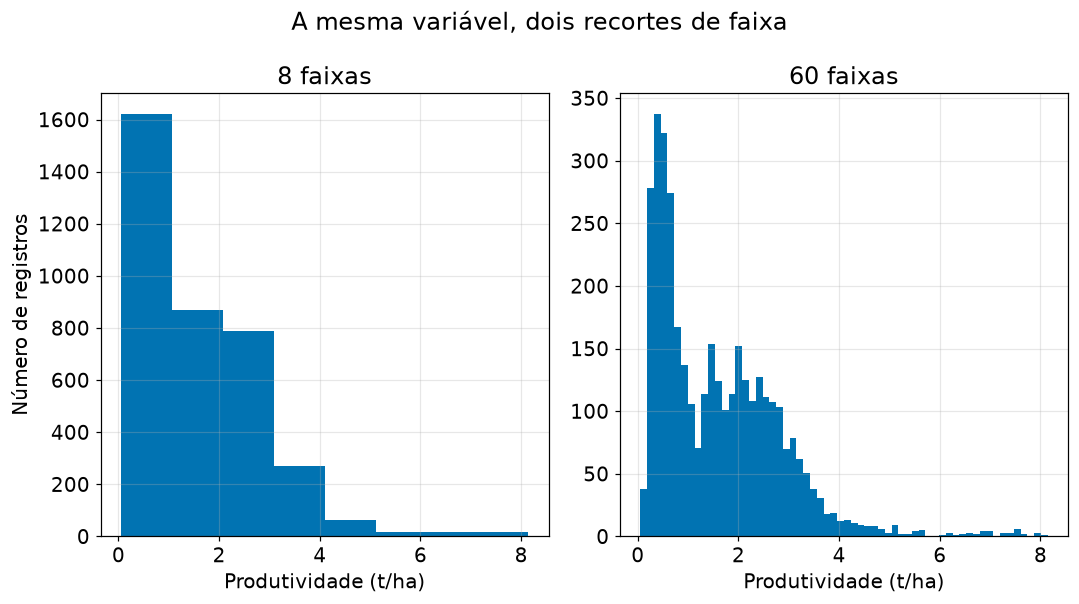

In [19]:
fig, eixos = plt.subplots(1, 2)   # sem sharey: faixas diferentes produzem contagens diferentes
for eixo, n_faixas in zip(eixos, [8, 60]):
    eixo.hist(dados["produtividade_t_ha"], bins=n_faixas, color=AZUL)
    eixo.set_title(f"{n_faixas} faixas")
    eixo.set_xlabel("Produtividade (t/ha)")
eixos[0].set_ylabel("Número de registros")
fig.suptitle("A mesma variável, dois recortes de faixa")
fig.tight_layout()
salvar(fig, "f4-1-histograma-binning.png")
plt.show()

## O mesmo dado, duas leituras

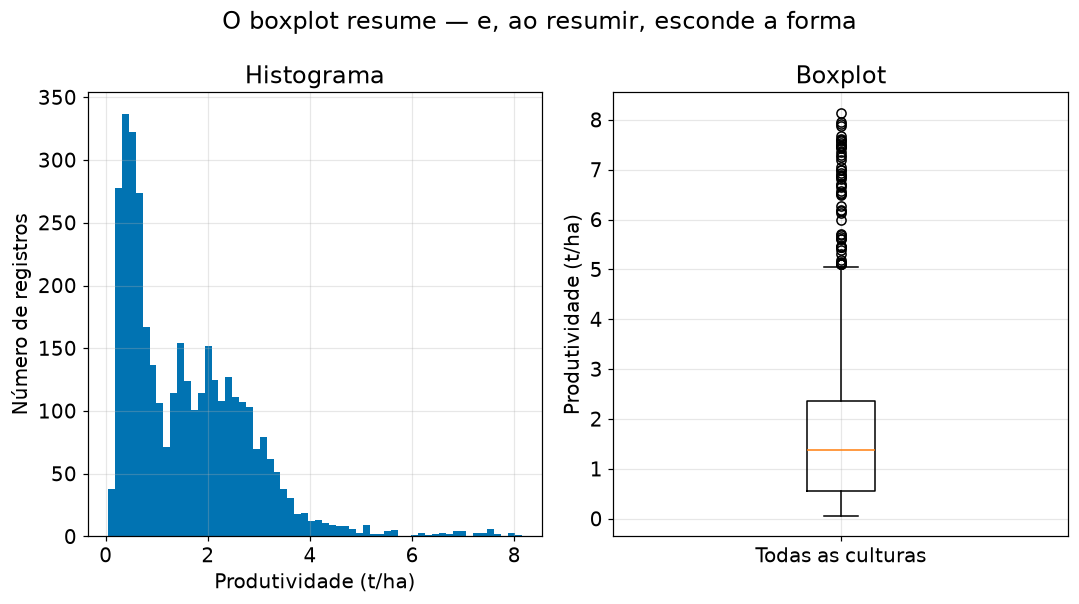

In [20]:
fig, eixos = plt.subplots(1, 2)
eixos[0].hist(dados["produtividade_t_ha"], bins=60, color=AZUL)
eixos[0].set_title("Histograma")
eixos[0].set_xlabel("Produtividade (t/ha)")
eixos[0].set_ylabel("Número de registros")

eixos[1].boxplot(dados["produtividade_t_ha"], tick_labels=["Todas as culturas"])
eixos[1].set_title("Boxplot")
eixos[1].set_ylabel("Produtividade (t/ha)")

fig.suptitle("O boxplot resume — e, ao resumir, esconde a forma")
fig.tight_layout()
salvar(fig, "f4-2-histograma-vs-boxplot.png")
plt.show()

## De onde vêm as duas corcovas

In [21]:
resumo_cultura = (dados.groupby("cultura")["produtividade_t_ha"]
                  .agg(n="count", mediana="median")
                  .sort_values("mediana")
                  .round(2))
display(resumo_cultura)

,n,mediana
cultura,,
Feijão-moth,107,0.40
Feijão-mungo,722,0.49
Feijão-urad,715,0.54
Milho,953,2.04
Arroz,1171,2.32


## A comparação entre grupos

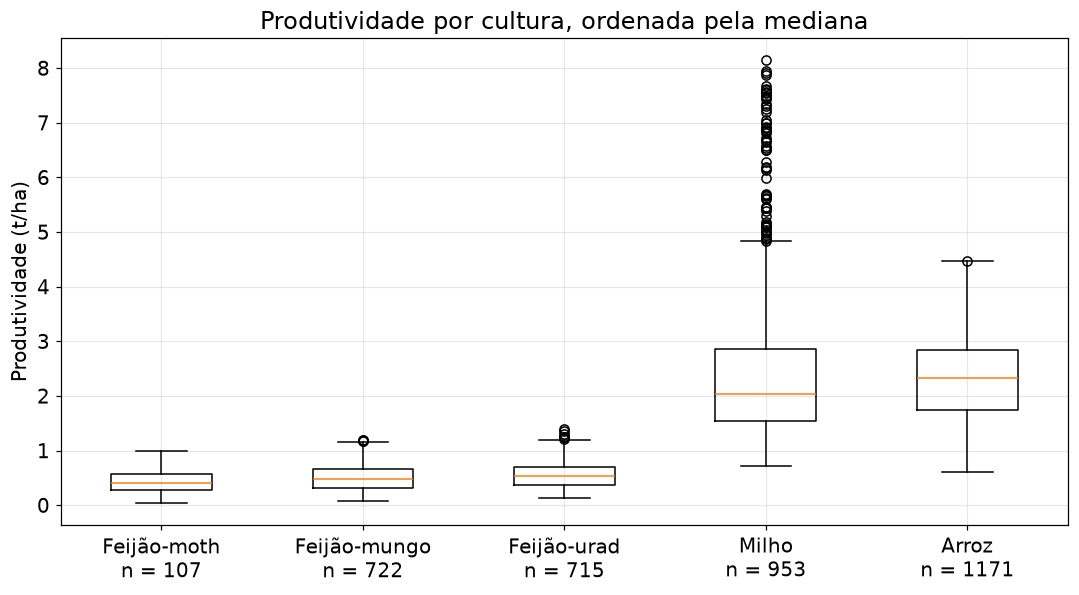

In [22]:
ordem = resumo_cultura.index.tolist()
grupos = [dados.loc[dados["cultura"] == cultura, "produtividade_t_ha"] for cultura in ordem]
rotulos = [f"{cultura}\nn = {resumo_cultura.loc[cultura, 'n']:.0f}" for cultura in ordem]

fig, ax = plt.subplots()
ax.boxplot(grupos, tick_labels=rotulos)
ax.set_ylabel("Produtividade (t/ha)")
ax.set_title("Produtividade por cultura, ordenada pela mediana")
fig.tight_layout()
salvar(fig, "f4-3-boxplot-cultura.png")
plt.show()

## Quando os pontos se empilham

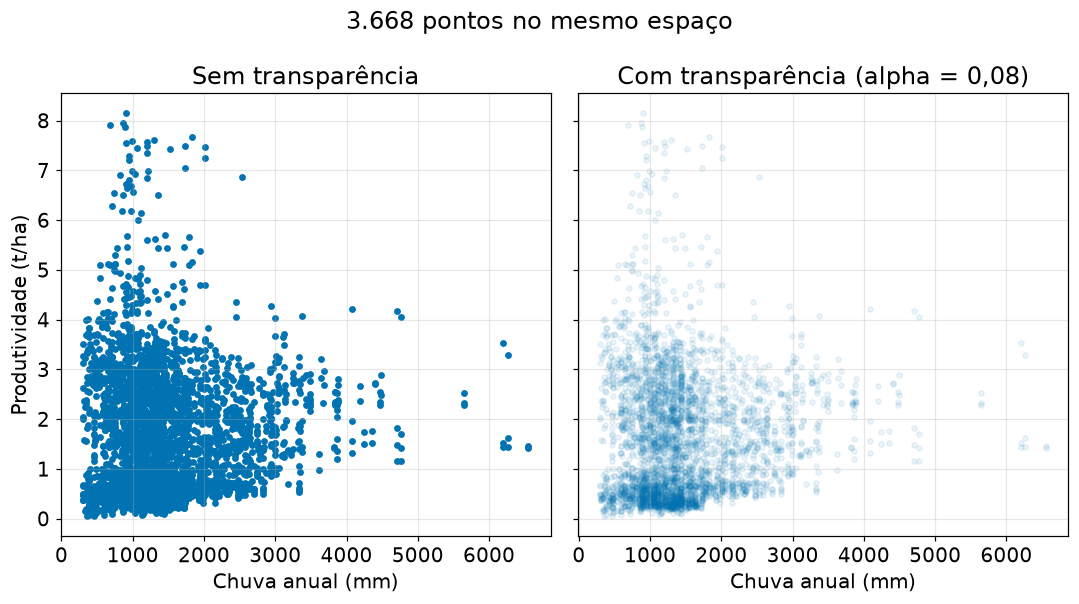

In [23]:
fig, eixos = plt.subplots(1, 2, sharey=True)
painel = [(1.0, "Sem transparência"), (0.08, "Com transparência (alpha = 0,08)")]
for eixo, (alfa, titulo) in zip(eixos, painel):
    eixo.scatter(dados["chuva_mm"], dados["produtividade_t_ha"],
                 s=12, color=AZUL, alpha=alfa)
    eixo.set_title(titulo)
    eixo.set_xlabel("Chuva anual (mm)")
eixos[0].set_ylabel("Produtividade (t/ha)")
fig.suptitle(f"{len(dados):,} pontos no mesmo espaço".replace(",", "."))
fig.tight_layout()
salvar(fig, "f4-4-overplotting-alpha.png")
plt.show()

## Quem anda junto com quem

In [24]:
NUMERICAS = ["area_ha", "producao_t", "produtividade_t_ha",
             "chuva_mm", "fertilizante_kg_ha", "defensivo_kg_ha"]
correlacoes = dados[NUMERICAS].corr()

display(correlacoes["produtividade_t_ha"]
        .drop("produtividade_t_ha")
        .sort_values(ascending=False)
        .round(2)
        .to_frame("correlação com a produtividade"))

,correlação com a produtividade
producao_t,0.32
area_ha,0.18
fertilizante_kg_ha,0.12
defensivo_kg_ha,0.10
chuva_mm,0.05


## A matriz inteira

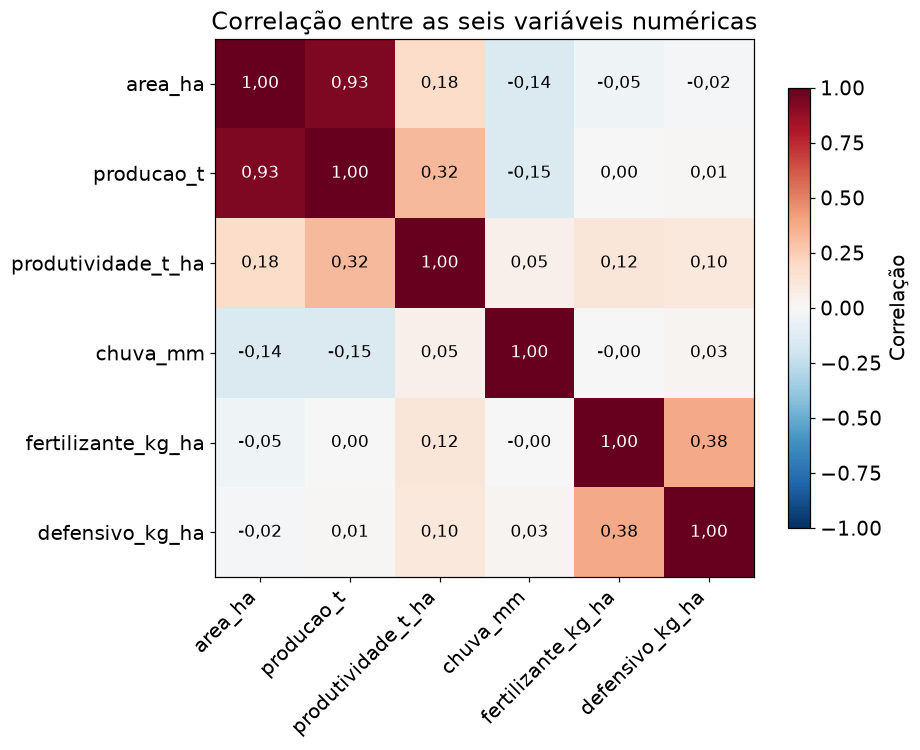

In [25]:
fig, ax = plt.subplots(figsize=(8.5, 7))
imagem = ax.imshow(correlacoes, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(NUMERICAS)), NUMERICAS, rotation=45, ha="right")
ax.set_yticks(range(len(NUMERICAS)), NUMERICAS)
for linha in range(len(NUMERICAS)):
    for coluna in range(len(NUMERICAS)):
        valor = correlacoes.iloc[linha, coluna]
        ax.text(coluna, linha, f"{valor:.2f}".replace(".", ","),
                ha="center", va="center", fontsize=11,
                color="white" if abs(valor) > 0.55 else "black")
ax.grid(False)
fig.colorbar(imagem, ax=ax, shrink=0.8, label="Correlação")
ax.set_title("Correlação entre as seis variáveis numéricas")
fig.tight_layout()
salvar(fig, "f4-5-matriz-correlacao.png")
plt.show()

## O que sobra quando o tempo sai

In [26]:
# a correlação bruta entre as duas taxas de manejo, contra a mesma correlação
# depois de remover a tendência de cada ano (comparando só o desvio de cada
# região em relação à média do seu próprio ano)
bruta = dados["fertilizante_kg_ha"].corr(dados["defensivo_kg_ha"])
media_do_ano = dados.groupby("ano")[["fertilizante_kg_ha", "defensivo_kg_ha"]].transform("mean")
sem_tendencia = (dados["fertilizante_kg_ha"] - media_do_ano["fertilizante_kg_ha"]).corr(
    dados["defensivo_kg_ha"] - media_do_ano["defensivo_kg_ha"])

display(pd.Series({"correlação bruta": bruta, "sem a tendência do ano": sem_tendencia})
        .round(2).to_frame("fertilizante × defensivo"))

,fertilizante × defensivo
correlação bruta,0.38
sem a tendência do ano,0.02


## A base ao longo do tempo

In [27]:
CULTURAS_SERIE = ["Arroz", "Feijão-mungo"]
serie = (dados[dados["cultura"].isin(CULTURAS_SERIE)]
         .pivot_table(index="ano", columns="cultura", values="produtividade_t_ha"))
display(serie.round(2).head())

cultura,Arroz,Feijão-mungo
ano,,
1997,1.96,0.44
1998,2.02,0.40
1999,2.07,0.46
2000,2.10,0.43
2001,2.11,0.43


## Duas linhas, uma leitura

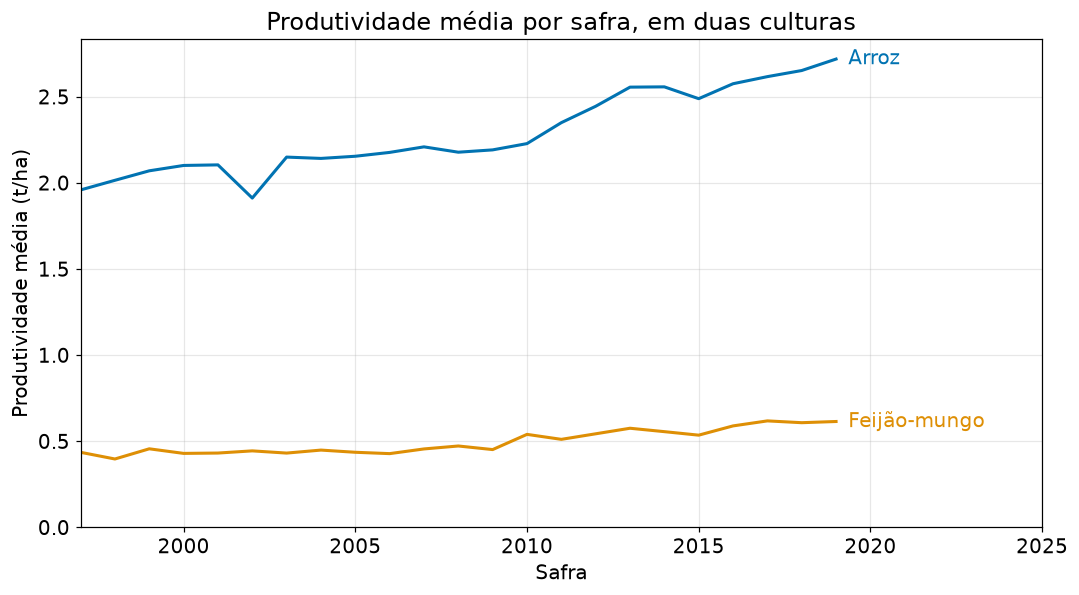

In [28]:
fig, ax = plt.subplots()
for cultura, cor in zip(CULTURAS_SERIE, [AZUL, LARANJA]):
    ax.plot(serie.index, serie[cultura], color=cor, linewidth=2)
    ax.annotate(cultura, (serie.index[-1], serie[cultura].iloc[-1]),
                xytext=(8, 0), textcoords="offset points", color=cor, va="center")
ax.set_xlim(serie.index.min(), serie.index.max() + 6)
ax.set_ylim(0, None)
ax.set_xlabel("Safra")
ax.set_ylabel("Produtividade média (t/ha)")
ax.set_title("Produtividade média por safra, em duas culturas")
fig.tight_layout()
salvar(fig, "f4-6-serie-temporal.png")
plt.show()

## O que ocupa a terra

In [29]:
area_por_cultura = dados.pivot_table(index="ano", columns="cultura",
                                     values="area_ha", aggfunc="sum")
participacao = area_por_cultura.div(area_por_cultura.sum(axis=1), axis=0) * 100
display(participacao.loc[[1997, 2019]].round(1))

cultura,Arroz,Feijão-moth,Feijão-mungo,Feijão-urad,Milho
ano,,,,,
1997,76.6,2.5,3.6,4.6,12.6
2019,75.7,0.0,3.2,6.6,14.5


## Composição, do jeito honesto

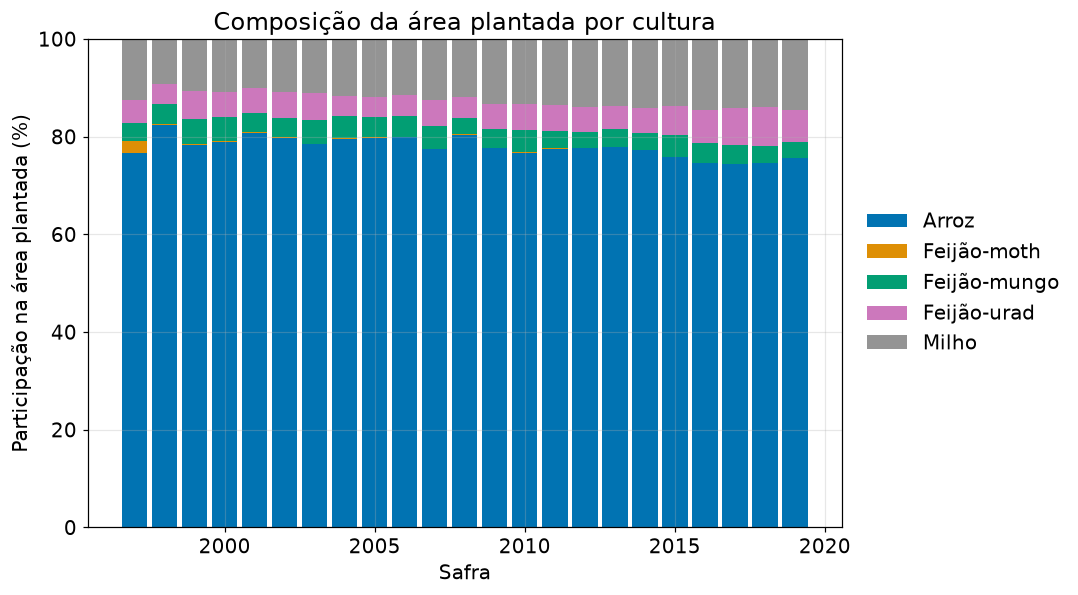

In [30]:
CORES_CULTURA = [AZUL, LARANJA, "#029E73", "#CC78BC", CINZA]

fig, ax = plt.subplots()
acumulado = 0
for cultura, cor in zip(participacao.columns, CORES_CULTURA):
    ax.bar(participacao.index, participacao[cultura], bottom=acumulado,
           color=cor, label=cultura, width=0.85)
    acumulado = acumulado + participacao[cultura]
ax.set_ylim(0, 100)
ax.set_xlabel("Safra")
ax.set_ylabel("Participação na área plantada (%)")
ax.set_title("Composição da área plantada por cultura")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)
fig.tight_layout()
salvar(fig, "f4-7-composicao-100.png")
plt.show()

## O que levamos daqui

Cinco tipos de gráfico, uma base só: distribuição, comparação entre grupos, relação, série temporal
e composição. Na próxima aula, o alvo deixa de ser o dado e passa a ser o **modelo**.